## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

In [2]:
data = pd.read_csv(r"Data/phishing_url_svm_ready_cleaned.csv")
data

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP,type
0,0.000000,0,0,0,0,0,0,0,0,1,...,89.999988,3653.0,104,5,0,8,1,22,0,phishing
1,0.366667,10,0,0,0,10,1,0,0,0,...,360.000000,7671.0,58,2,2,4,0,10,0,benign
2,0.000000,0,0,0,0,0,0,0,0,0,...,89.999988,4748.0,12,2,0,0,0,2,0,phishing
3,0.000000,0,0,0,0,0,0,0,0,0,...,365.000000,7671.0,14,1,0,0,0,1,0,phishing
4,0.288032,102,0,0,2,93,44,1,1,0,...,89.999988,8401.0,73,2,1,2,12,12,0,benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,0.000000,0,0,0,0,0,0,0,0,0,...,89.999988,3287.0,59,3,6,1,0,10,0,benign
789,0.136364,5,0,0,0,5,1,0,0,1,...,89.999988,3652.0,81,3,3,7,1,14,0,phishing
790,0.087413,1,0,0,1,0,24,0,0,0,...,89.999988,9131.0,52,2,2,2,0,8,0,benign
791,0.341463,36,0,0,3,28,80,0,0,0,...,393.999988,8036.0,30,1,0,3,0,4,0,benign


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 793 entries, 0 to 792
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Link Density               793 non-null    float64
 1   External Links Count       793 non-null    int64  
 2   Internal Links Count       793 non-null    int64  
 3   External IP Count          793 non-null    int64  
 4   HTTP Count                 793 non-null    int64  
 5   HTTPS Count                793 non-null    int64  
 6   Non Count                  793 non-null    int64  
 7   External Iframes Count     793 non-null    int64  
 8   Hidden Iframes Count       793 non-null    int64  
 9   If HTTPS                   793 non-null    int64  
 10  Country                    793 non-null    object 
 11  Organization               793 non-null    object 
 12  Certificate                793 non-null    object 
 13  Whois_country              793 non-null    object 

## Separate Features and Target variable

In [4]:
X = data.drop(columns=['type'])
y= data['type']

In [5]:
X

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Whois_country,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP
0,0.000000,0,0,0,0,0,0,0,0,1,...,CR,89.999988,3653.0,104,5,0,8,1,22,0
1,0.366667,10,0,0,0,10,1,0,0,0,...,US,360.000000,7671.0,58,2,2,4,0,10,0
2,0.000000,0,0,0,0,0,0,0,0,0,...,IN,89.999988,4748.0,12,2,0,0,0,2,0
3,0.000000,0,0,0,0,0,0,0,0,0,...,US,365.000000,7671.0,14,1,0,0,0,1,0
4,0.288032,102,0,0,2,93,44,1,1,0,...,Unknown,89.999988,8401.0,73,2,1,2,12,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,0.000000,0,0,0,0,0,0,0,0,0,...,US,89.999988,3287.0,59,3,6,1,0,10,0
789,0.136364,5,0,0,0,5,1,0,0,1,...,Unknown,89.999988,3652.0,81,3,3,7,1,14,0
790,0.087413,1,0,0,1,0,24,0,0,0,...,Unknown,89.999988,9131.0,52,2,2,2,0,8,0
791,0.341463,36,0,0,3,28,80,0,0,0,...,Unknown,393.999988,8036.0,30,1,0,3,0,4,0


In [6]:
y

0      phishing
1        benign
2      phishing
3      phishing
4        benign
         ...   
788      benign
789    phishing
790      benign
791      benign
792      benign
Name: type, Length: 793, dtype: object

## Find Numerical and Categorical Features

In [7]:
numerical_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

In [8]:
numerical_features

['Link Density',
 'External Links Count',
 'Internal Links Count',
 'External IP Count',
 'HTTP Count',
 'HTTPS Count',
 'Non Count',
 'External Iframes Count',
 'Hidden Iframes Count',
 'If HTTPS',
 'Certificate Validity Days',
 'Domain Validity Days',
 'URL Length',
 'URL Dot Count',
 'URL Hyphen Count',
 'URL Slash Count',
 'URL Digit Count',
 'URL Special Char Count',
 'URL Has IP']

In [9]:
categorical_features

['Country', 'Organization', 'Certificate', 'Whois_country']

## Encode the target variable

In [10]:
le = LabelEncoder()

In [11]:
y = le.fit_transform(y)
y

array([1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,

## Split the data

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
X_train

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Whois_country,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP
681,0.000000,0,0,0,0,0,0,0,0,0,...,US,394.999988,7671.0,23,1,0,1,0,3,0
2,0.000000,0,0,0,0,0,0,0,0,0,...,IN,89.999988,4748.0,12,2,0,0,0,2,0
777,0.444444,0,0,0,0,0,40,0,0,1,...,Unknown,89.999988,3287.0,70,5,0,10,4,16,0
726,0.097959,23,0,0,0,23,1,0,0,1,...,US,89.999988,7671.0,111,3,1,14,10,19,0
591,0.007874,1,0,0,0,1,0,0,0,0,...,Unknown,89.999988,10591.0,25,1,0,2,3,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,0.162162,10,0,0,0,10,2,0,0,0,...,Error,89.999988,7671.0,17,2,0,0,3,2,0
750,0.010309,1,0,0,0,1,0,0,0,0,...,US,397.000000,7671.0,70,1,7,2,4,10,0
752,0.031250,0,0,0,0,0,1,0,0,0,...,US,394.999988,7671.0,142,2,22,5,12,29,0
771,0.101804,24,39,0,1,41,37,1,1,0,...,US,396.999988,7671.0,57,1,4,2,7,8,0


In [14]:
X_test

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Whois_country,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP
355,0.041607,10,6,0,15,1,12,1,0,0,...,US,89.999988,7671.000000,17,1,0,1,0,2,0
323,0.139942,34,0,0,34,0,62,0,0,0,...,US,395.999988,12053.000000,63,2,3,4,0,9,0
469,0.071429,1,0,0,1,0,1,0,0,0,...,US,90.999988,7671.000000,50,1,6,2,3,9,0
633,0.000000,0,0,0,0,0,0,0,0,0,...,BR,89.999988,7671.000000,20,2,0,0,0,2,0
222,0.074766,8,0,0,0,8,0,0,0,1,...,BR,89.999988,7671.000000,39,2,0,5,0,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
248,0.000000,0,0,0,0,0,0,0,0,1,...,BR,89.999988,7671.000000,40,2,0,4,2,7,0
400,0.026923,1,0,0,0,1,13,0,0,0,...,US,365.000000,7671.000000,27,1,0,0,0,1,0
4,0.288032,102,0,0,2,93,44,1,1,0,...,Unknown,89.999988,8401.000000,73,2,1,2,12,12,0
251,0.000000,0,0,0,0,0,0,0,0,1,...,US,89.999988,7671.000000,40,2,0,4,1,7,0


In [15]:
y_train

array([0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1,

In [16]:
y_test

array([0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 0])

## Feature Preprocessing using ColumnTransformer

In [17]:
preprocessor = ColumnTransformer(
    transformers = [
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

In [18]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


## Create SVM Pipeline

In [19]:
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC())
])

In [20]:
svm_pipeline

,steps,"[('preprocessor', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Train the model

In [21]:
svm_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Make predictions

In [22]:
y_pred = svm_pipeline.predict(X_test)
y_pred

array([1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 0])

## Evaluate the basic SVM

In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.9371069182389937
Precision: 0.9069767441860465
Recall: 0.975
F1 Score: 0.9397590361445783


### Insights
- The SVM model achieved an accuracy of **93.71%**, meaning that approximately 94% of the test samples were classified correctly.
- The model achieved a precision of **90.70%**, indicating that when the model predicted the positive class (Yes), about **91%** of those predictions were actually positive.
- The recall of **97.50%** shows that the model correctly identified **97.5%** of the actual positive cases. This is particularly useful when the goal is to minimize missed positive cases.
- The F1-score of **93.98%** indicates a good balance between precision and recall.

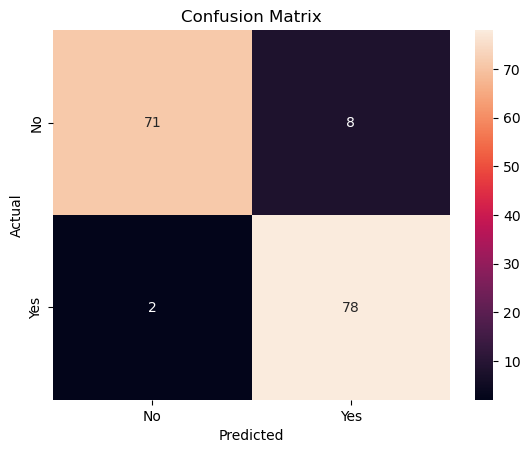

In [24]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

- The SVM model performed well on the test set, correctly classifying **149** out of **159** observations. It identified most of the actual positive cases, with only **2** false negatives, while producing **8** false positives. The high recall of **97.5%** indicates that the model was effective at detecting the positive class.

## Test Different Kernals

In [25]:
kernels = ['linear', 'rbf', 'poly']

for kernel in kernels:
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('svm', SVC(kernel=kernel))
    ])
    
    model.fit(X_train, y_train)
    
    y_pred_kernel = model.predict(X_test)
    
    print(f"\nKernel: {kernel}")
    print("Accuracy:", accuracy_score(y_test, y_pred_kernel))
    print("Precision:", precision_score(y_test, y_pred_kernel))
    print("Recall:", recall_score(y_test, y_pred_kernel))
    print("F1 Score:", f1_score(y_test, y_pred_kernel))


Kernel: linear
Accuracy: 0.9056603773584906
Precision: 0.891566265060241
Recall: 0.925
F1 Score: 0.9079754601226994

Kernel: rbf
Accuracy: 0.9371069182389937
Precision: 0.9069767441860465
Recall: 0.975
F1 Score: 0.9397590361445783

Kernel: poly
Accuracy: 0.8930817610062893
Precision: 0.8705882352941177
Recall: 0.925
F1 Score: 0.896969696969697


| Kernel     |   Accuracy |  Precision |     Recall |   F1 Score |
| ---------- | ---------: | ---------: | ---------: | ---------: |
| Linear     |     90.57% |     89.16% |     92.50% |     90.80% |
| **RBF**    | **93.71%** | **90.70%** | **97.50%** | **93.98%** |
| Polynomial |     89.31% |     87.06% |     92.50% |     89.70% |

- The linear kernel achieved moderate performance, while the polynomial kernel produced comparatively lower results. The RBF kernel was therefore selected for further hyperparameter tuning.

## Hyperparameter Tuning

In [26]:
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__kernel': ['linear', 'rbf', 'poly'],
    'svm__gamma': ['scale', 'auto']
}

In [27]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [28]:
grid_search

,estimator,"Pipeline(step...svm', SVC())])"
,param_grid,"{'svm__C': [0.1, 1, ...], 'svm__gamma': ['scale', 'auto'], 'svm__kernel': ['linear', 'rbf', ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [29]:
grid_search.fit(X_train, y_train)

,estimator,"Pipeline(step...svm', SVC())])"
,param_grid,"{'svm__C': [0.1, 1, ...], 'svm__gamma': ['scale', 'auto'], 'svm__kernel': ['linear', 'rbf', ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [30]:
# 1. Best parameters
print("Best Parameters:", grid_search.best_params_)

# 2. Best CV score
print("Best CV F1 Score:", grid_search.best_score_)

# 3. Get best model
best_model = grid_search.best_estimator_

# 4. Predict on test data
y_pred_tuned = best_model.predict(X_test)

# 5. Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

Best Parameters: {'svm__C': 100, 'svm__gamma': 'auto', 'svm__kernel': 'rbf'}
Best CV F1 Score: 0.9813649937190727
Accuracy: 0.9811320754716981
Precision: 0.963855421686747
Recall: 1.0
F1 Score: 0.9815950920245399


- GridSearchCV was used to identify the optimal SVM hyperparameters. The best-performing configuration was an RBF kernel with C = 100 and gamma = 'auto'. The best cross-validation F1-score was 98.14%. On the test set, the tuned SVM achieved 98.11% accuracy, 96.39% precision, 100% recall, and 98.16% F1-score, showing a substantial improvement over the baseline RBF model.

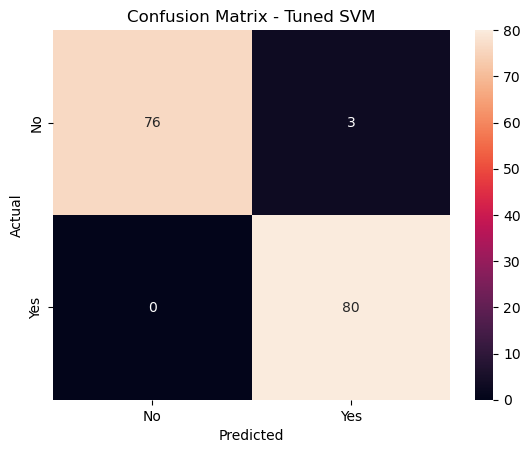

In [31]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tuned SVM')
plt.show()

- Hyperparameter tuning substantially improved the SVM's performance. The tuned model correctly identified all 80 positive cases in the test set, resulting in 100% recall, while only 3 negative cases were incorrectly classified as positive. The increase in F1-score from 93.98% to 98.16% indicates an improved balance between precision and recall.

## ROC-AUC (Receiver Operating Characteristic – Area Under the Curve)

In [32]:
y_score_tuned = best_model.decision_function(X_test)
y_score_tuned

array([-0.42908149, -5.80758918, -3.49573928,  1.56717998,  2.54836269,
        1.38355425,  1.52126265, -3.17446986, -1.11640019,  2.84822351,
       -2.4106967 , -1.74789461,  1.0127156 , -1.38420558, -5.09117739,
        1.57100043, -1.89489188,  0.70746696, -1.75431596,  2.31147896,
        3.89815878,  1.33427464, -0.69995546,  0.96187346, -3.00666559,
        0.99626366, -1.09631502,  1.12744704, -5.15265957, -1.47424099,
        2.23424841, -4.08270574, -2.19096027, -2.64732548,  2.16313057,
        1.03481356, -0.45654455,  0.13794912, -5.53104915,  3.12030294,
       -7.34076654, -2.85718511, -4.05334832, -0.50691727,  2.7747223 ,
       -2.66207654,  1.57682927, -4.74474799,  2.79582396,  1.46537477,
       -2.01411432,  1.19970482, -3.26089143,  1.18102677,  1.48662593,
        3.48190607,  2.03341231,  0.98735011, -0.55861191,  1.14782138,
       -0.47833891, -6.45962976,  1.61561945,  1.31990667,  1.00239208,
       -2.00456858,  0.7473931 , -3.48750223,  1.00859798,  1.66

In [33]:
roc_auc_tuned = roc_auc_score(y_test, y_score_tuned)

print("ROC-AUC Score:", roc_auc_tuned)

ROC-AUC Score: 0.9962025316455696


## Create ROC Curve

In [34]:
from sklearn.metrics import roc_curve

In [35]:
fpr, tpr, thresholds = roc_curve(y_test, y_score_tuned)

In [36]:
fpr, tpr, thresholds

(array([0.        , 0.        , 0.        , 0.01265823, 0.01265823,
        0.02531646, 0.02531646, 1.        ]),
 array([0.    , 0.0125, 0.725 , 0.725 , 0.975 , 0.975 , 1.    , 1.    ]),
 array([        inf,  3.89815878,  1.06217195,  1.04297011,  0.7473931 ,
         0.71657799,  0.52464332, -7.79886148]))

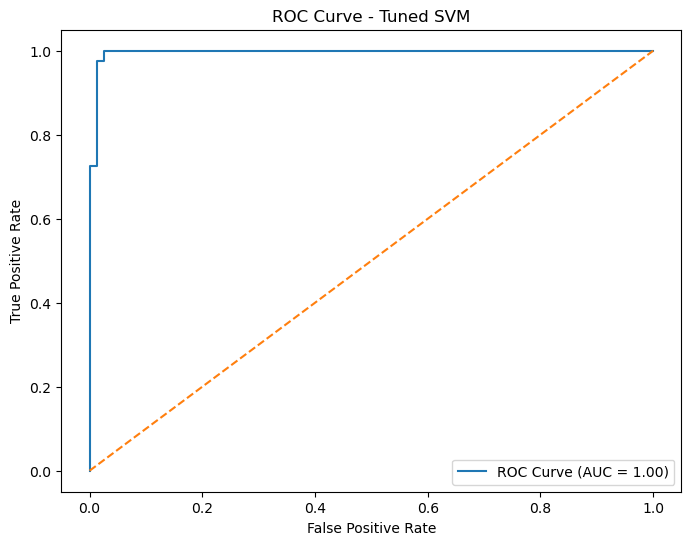

In [37]:
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_tuned:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--')  # this creates a diagonal dashed line from (0,0) to (1,1)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned SVM')
plt.legend()

plt.show()

- The ROC curve was plotted to evaluate the tuned SVM's ability to distinguish between the two classes across different classification thresholds. The model achieved a ROC-AUC score of 0.9962, indicating excellent class-separation performance on the test set. The ROC curve is very close to the top-left corner, showing a high true-positive rate with a very low false-positive rate across most thresholds.

### Final Model Performance
| Metric    |  Tuned SVM |
| --------- | ---------: |
| Accuracy  | **98.11%** |
| Precision | **96.39%** |
| Recall    |   **100%** |
| F1 Score  | **98.16%** |
| ROC-AUC   | **99.62%** |


## Save the tuned model

In [38]:
import joblib

In [39]:
joblib.dump(best_model, r"Model\phishing_svm_model.joblib")

['Model\\phishing_svm_model.joblib']

In [1]:
import sklearn
print(sklearn.__version__)

1.7.2


In [2]:
import sys
print(sys.version)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [3]:
import sys
import sklearn

print("Python:", sys.version)
print("Python path:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python path: C:\Users\Lenovo\anaconda3\python.exe
Scikit-learn: 1.7.2
